In [1]:
# Zachary Katz
# zachary_katz@mines.edu
# 11 November 2026

"""
Programatically download n tracks of SWOT L3_LR_SSH_Expert data for all available
cycles, clean, and calculate tides in an harmonic inversion.
"""

# Imports
import altimetry_downloader_aviso
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import xarray as xr
import matplotlib.pyplot as plt
from cartopy import crs as ccrs
import cartopy.feature as cfeature
import numpy as np
from utide import solve
import matplotlib.dates as mdates
from joblib import Parallel, delayed
import pyTMD
import getpass

In [23]:
import ftplib, getpass, pathlib, threading, time, logging
import pyTMD.datasets

user = "zachary_katz@mines.edu"
password = getpass.getpass("AVISO FTP password: ")
directory = pathlib.Path("~/tide_models").expanduser()
host = "ftp-access.aviso.altimetry.fr"
remote = "auxiliary/tide_model/fes2022b/ocean_tide_20241025"

# 1. stage timing + raw speed test (~20 MB of the first file, then abort)
t = time.time()
f = ftplib.FTP(host, timeout=30); print(f"connect: {time.time()-t:.1f}s")
t = time.time(); f.login(user, password); print(f"login: {time.time()-t:.1f}s")
t = time.time(); names = sorted(f.nlst(remote)); print(f"list: {time.time()-t:.1f}s, {len(names)} files")
f.voidcmd("TYPE I")
print("first file size:", f.size(names[0]) / 1e6, "MB")

class Stop(Exception): pass
got = 0; t0 = time.time()
def cb(chunk):
    global got
    got += len(chunk)
    if got >= 20e6: raise Stop
try:
    f.retrbinary(f"RETR {names[0]}", cb, blocksize=1 << 20)
except Stop:
    rate = got / (time.time() - t0) / 1e6
    print(f"raw speed: {rate:.2f} MB/s -> ~{170/rate/60:.1f} min per 170 MB file")
try: f.close()
except Exception: pass

#Run pyTMD in a thread with logging and a timeout; monitor from main thread
logging.basicConfig(level=logging.INFO)
def run():
    try:
        pyTMD.datasets.fetch_aviso_fes(model="FES2022", directory=directory,
                                       user=user, password=password, timeout=60)
    except Exception as e:
        print("\npyTMD raised:", repr(e))
th = threading.Thread(target=run, daemon=True); th.start()

def dir_size(p):
    return sum(x.stat().st_size for x in p.rglob("*") if x.is_file()) if p.exists() else 0

try:
    import psutil
    net = lambda: psutil.net_io_counters().bytes_recv
except ImportError:
    net = None

last_net = net() if net else 0; last_t = time.time(); start = last_t
while th.is_alive():
    time.sleep(5)
    now = time.time()
    msg = f"[{now-start:4.0f}s] on disk: {dir_size(directory)/1e6:.0f} MB"
    if net:
        cur = net(); msg += f" | net in: {(cur-last_net)/(now-last_t)/1e6:.2f} MB/s"; last_net = cur
    last_t = now
    print(msg)
print("done")

connect: 0.6s
login: 0.4s
list: 1.8s, 34 files
first file size: 153.913728 MB
raw speed: 0.18 MB/s -> ~15.5 min per 170 MB file


INFO:pyTMD.datasets.fetch_aviso_fes:ftp://ftp-access.aviso.altimetry.fr/auxiliary/tide_model/fes2022b/ocean_tide_20241025/2n2_fes2022.nc.xz -->
INFO:pyTMD.datasets.fetch_aviso_fes:ftp://ftp-access.aviso.altimetry.fr/auxiliary/tide_model/fes2022b/ocean_tide_20241025/eps2_fes2022.nc.xz -->
INFO:pyTMD.datasets.fetch_aviso_fes:ftp://ftp-access.aviso.altimetry.fr/auxiliary/tide_model/fes2022b/ocean_tide_20241025/j1_fes2022.nc.xz -->
INFO:pyTMD.datasets.fetch_aviso_fes:ftp://ftp-access.aviso.altimetry.fr/auxiliary/tide_model/fes2022b/ocean_tide_20241025/k1_fes2022.nc.xz -->
INFO:pyTMD.datasets.fetch_aviso_fes:ftp://ftp-access.aviso.altimetry.fr/auxiliary/tide_model/fes2022b/ocean_tide_20241025/k2_fes2022.nc.xz -->
INFO:pyTMD.datasets.fetch_aviso_fes:ftp://ftp-access.aviso.altimetry.fr/auxiliary/tide_model/fes2022b/ocean_tide_20241025/l2_fes2022.nc.xz -->
INFO:pyTMD.datasets.fetch_aviso_fes:ftp://ftp-access.aviso.altimetry.fr/auxiliary/tide_model/fes2022b/ocean_tide_20241025/lambda2_fes2022.n

[   5s] on disk: 3809 MB | net in: 0.05 MB/s


INFO:pyTMD.datasets.fetch_aviso_fes:ftp://ftp-access.aviso.altimetry.fr/auxiliary/tide_model/fes2022b/ocean_tide_20241025/o1_fes2022.nc.xz -->
INFO:pyTMD.datasets.fetch_aviso_fes:	/home/zkatz/tide_models/fes2022b/ocean_tide_20241025/o1_fes2022.nc


[  10s] on disk: 3809 MB | net in: 0.20 MB/s
[  15s] on disk: 3809 MB | net in: 0.24 MB/s
[  18s] on disk: 3809 MB | net in: 0.39 MB/s
[  23s] on disk: 3809 MB | net in: 0.23 MB/s
[  28s] on disk: 3809 MB | net in: 0.23 MB/s
[  33s] on disk: 3809 MB | net in: 0.25 MB/s
[  38s] on disk: 3809 MB | net in: 0.25 MB/s
[  43s] on disk: 3809 MB | net in: 0.17 MB/s
[  48s] on disk: 3809 MB | net in: 0.23 MB/s
[  51s] on disk: 3809 MB | net in: 0.35 MB/s
[  56s] on disk: 3809 MB | net in: 0.20 MB/s
[  61s] on disk: 3809 MB | net in: 0.18 MB/s
[  66s] on disk: 3809 MB | net in: 0.18 MB/s
[  71s] on disk: 3809 MB | net in: 0.18 MB/s
[  76s] on disk: 3809 MB | net in: 0.17 MB/s
[  79s] on disk: 3809 MB | net in: 0.29 MB/s
[  85s] on disk: 3809 MB | net in: 0.19 MB/s
[  90s] on disk: 3809 MB | net in: 0.18 MB/s
[  95s] on disk: 3809 MB | net in: 0.17 MB/s
[ 100s] on disk: 3809 MB | net in: 0.19 MB/s
[ 105s] on disk: 3809 MB | net in: 0.18 MB/s
[ 108s] on disk: 3809 MB | net in: 0.27 MB/s
[ 113s] on

INFO:pyTMD.datasets.fetch_aviso_fes:ftp://ftp-access.aviso.altimetry.fr/auxiliary/tide_model/fes2022b/ocean_tide_20241025/p1_fes2022.nc.xz -->
INFO:pyTMD.datasets.fetch_aviso_fes:	/home/zkatz/tide_models/fes2022b/ocean_tide_20241025/p1_fes2022.nc


... (13 outputs left out)

INFO:pyTMD.datasets.fetch_aviso_fes:ftp://ftp-access.aviso.altimetry.fr/auxiliary/tide_model/fes2022b/ocean_tide_20241025/ssa_fes2022.nc.xz -->
INFO:pyTMD.datasets.fetch_aviso_fes:	/home/zkatz/tide_models/fes2022b/ocean_tide_20241025/ssa_fes2022.nc


[6280s] on disk: 5033 MB | net in: 0.11 MB/s
[6282s] on disk: 5033 MB | net in: 0.27 MB/s
[6287s] on disk: 5033 MB | net in: 0.17 MB/s
[6292s] on disk: 5033 MB | net in: 0.17 MB/s
[6298s] on disk: 5033 MB | net in: 0.18 MB/s
[6303s] on disk: 5033 MB | net in: 0.17 MB/s
[6308s] on disk: 5033 MB | net in: 0.16 MB/s
[6313s] on disk: 5033 MB | net in: 0.18 MB/s
[6316s] on disk: 5033 MB | net in: 0.26 MB/s
[6321s] on disk: 5033 MB | net in: 0.18 MB/s
[6326s] on disk: 5033 MB | net in: 0.16 MB/s
[6331s] on disk: 5033 MB | net in: 0.16 MB/s
[6336s] on disk: 5033 MB | net in: 0.17 MB/s
[6341s] on disk: 5033 MB | net in: 0.20 MB/s
[6344s] on disk: 5033 MB | net in: 0.28 MB/s
[6349s] on disk: 5033 MB | net in: 0.18 MB/s
[6354s] on disk: 5033 MB | net in: 0.17 MB/s
[6359s] on disk: 5033 MB | net in: 0.17 MB/s
[6364s] on disk: 5033 MB | net in: 0.19 MB/s
[6369s] on disk: 5033 MB | net in: 0.17 MB/s
[6372s] on disk: 5033 MB | net in: 0.30 MB/s
[6377s] on disk: 5033 MB | net in: 0.19 MB/s
[6382s] on

INFO:pyTMD.datasets.fetch_aviso_fes:ftp://ftp-access.aviso.altimetry.fr/auxiliary/tide_model/fes2022b/ocean_tide_20241025/t2_fes2022.nc.xz -->
INFO:pyTMD.datasets.fetch_aviso_fes:	/home/zkatz/tide_models/fes2022b/ocean_tide_20241025/t2_fes2022.nc


[6994s] on disk: 5162 MB | net in: 0.14 MB/s
[6999s] on disk: 5162 MB | net in: 0.45 MB/s
[7004s] on disk: 5162 MB | net in: 0.18 MB/s
[7008s] on disk: 5162 MB | net in: 0.27 MB/s
[7013s] on disk: 5162 MB | net in: 0.22 MB/s
[7018s] on disk: 5162 MB | net in: 0.19 MB/s
[7023s] on disk: 5162 MB | net in: 0.19 MB/s
[7028s] on disk: 5162 MB | net in: 0.19 MB/s
[7033s] on disk: 5162 MB | net in: 0.20 MB/s
[7038s] on disk: 5162 MB | net in: 0.23 MB/s
[7042s] on disk: 5162 MB | net in: 0.23 MB/s
[7047s] on disk: 5162 MB | net in: 0.19 MB/s
[7052s] on disk: 5162 MB | net in: 0.21 MB/s
[7057s] on disk: 5162 MB | net in: 0.19 MB/s
[7062s] on disk: 5162 MB | net in: 0.21 MB/s
[7067s] on disk: 5162 MB | net in: 0.19 MB/s
[7071s] on disk: 5162 MB | net in: 0.24 MB/s
[7076s] on disk: 5162 MB | net in: 0.20 MB/s
[7081s] on disk: 5162 MB | net in: 0.19 MB/s
[7086s] on disk: 5162 MB | net in: 0.20 MB/s
[7091s] on disk: 5162 MB | net in: 0.19 MB/s
[7096s] on disk: 5162 MB | net in: 0.17 MB/s
[7101s] on

In [2]:
# Load model 
model_dir = "/mnt/c/Users/ZacharyKatz/Desktop/Research/Background/"    
model_name = "FES2022"
constits = ["M2", "S2", "N2", "K2", "K1", "O1", "P1", "Q1"]
names = [c.lower() for c in constits]

m = pyTMD.io.model(model_dir).from_database(model_name)

ds = m.open_dataset(
    group="z",
    chunks={"lat": 500, "lon": 500}
)
ds = ds[names]
ds.load()
#m = pyTMD.io.model(model_dir).from_database(model_name)
#print(m)      
#ds = m.open_dataset(group="z")

<xarray.Dataset> Size: 4GB
Dimensions:  (y: 5401, x: 10801)
Coordinates:
  * y        (y) float64 43kB -90.0 -89.97 -89.93 -89.9 ... 89.93 89.97 90.0
  * x        (x) float64 86kB 0.0 0.03333 0.06667 0.1 ... 359.9 360.0 360.0
Data variables:
    m2       (y, x) complex64 467MB (nan+nanj) ... (0.022336783-0.05082071j)
    s2       (y, x) complex64 467MB (nan+nanj) ... (-0.009476421-0.026188971j)
    n2       (y, x) complex64 467MB (nan+nanj) ... (0.0077381134-0.0056956103j)
    k2       (y, x) complex64 467MB (nan+nanj) ... (-0.0029030542-0.0069143707j)
    k1       (y, x) complex64 467MB (nan+nanj) ... (0.028285591+0.0017278494j)
    o1       (y, x) complex64 467MB (nan+nanj) ... (0.013566077+0.0071121454j)
    p1       (y, x) complex64 467MB (nan+nanj) ... (0.008964002+0.0009412244j)
    q1       (y, x) complex64 467MB (nan+nanj) ... (0.0018100627+0.00089757144j)
Attributes:
    group:    z
    lineage:  ['2n2_fes2022.nc', 'eps2_fes2022.nc', 'j1_fes2022.nc', 'k1_fes2...
    source:   FES2022
    crs:      {'proj': 'longlat', 'datum': 'WGS84', 'ellps': 'WGS84', 'lon_wr...

In [4]:
# Plot FES for 8 constitutents on 1 degree grid
def got_constants(lon, lat, names, batch=20000):
    """Pointwise interpolation. Returns amp (m) and Greenwich phase (deg), shape (n_const, n_points)."""
    n = lon.size
    amp = np.full((len(names), n), np.nan)
    ph = np.full((len(names), n), np.nan)
    for s in range(0, n, batch):
        sl = slice(s, min(s + batch, n))
        x = xr.DataArray(lon[sl], dims="points")
        y = xr.DataArray(lat[sl], dims="points")
        local = ds.tmd.interp(x, y, extrapolate=True)
        hc = np.stack([np.asarray(local[c].values) for c in names])
        assert hc.shape == (len(names), sl.stop - sl.start), hc.shape   # catches the grid case early
        amp[:, sl] = np.abs(hc)
        ph[:, sl] = np.degrees(np.arctan2(-hc.imag, hc.real)) % 360
    return amp, ph

lon = np.arange(0, 360, 1)
lat = np.arange(-90, 90, 1)
grid = np.meshgrid(lon, lat)
lon_raveled = grid[0].ravel()
lat_raveled = grid[1].ravel()


amp, ph = got_constants(lon_raveled, lat_raveled, names)
    

In [5]:
def get_spilhaus_mask(lon2d, lat2d, projection):
    # Transform geographic coordinates into Spilhaus coordinates
    xy = projection.transform_points(
        ccrs.PlateCarree(), lon2d, lat2d
    )
    x = xy[..., 0]
    y = xy[..., 1]

    bound = np.mean(np.abs(np.asarray(projection.bounds)))

    # Identify points near the projection boundary
    near_bound = (
        (np.abs(x) > 0.95 * bound) |
        (np.abs(y) > 0.95 * bound)
    )

    # Rotate coordinates to align with the projection boundary
    theta = np.deg2rad(45)
    rot_x = x * np.cos(theta) - y * np.sin(theta)
    rot_y = y * np.cos(theta) + x * np.sin(theta)

    # Detect sign changes across cell diagonals
    change_sign0 = (
        (rot_x[1:, 1:] * rot_x[:-1, :-1] < 0) |
        (rot_y[1:, 1:] * rot_y[:-1, :-1] < 0)
    )

    change_sign1 = (
        (rot_x[1:, :-1] * rot_x[:-1, 1:] < 0) |
        (rot_y[1:, :-1] * rot_y[:-1, 1:] < 0)
    )

    change_sign = change_sign0 | change_sign1

    # Expand the mask to all four corners of affected cells
    sign_change = np.zeros_like(x, dtype=bool)

    sign_change[1:, 1:] |= change_sign
    sign_change[:-1, :-1] |= change_sign
    sign_change[1:, :-1] |= change_sign
    sign_change[:-1, 1:] |= change_sign

    return near_bound & sign_change

Plotting M2
Plotting S2
Plotting N2
Plotting K2
Plotting K1
Plotting O1
Plotting P1
Plotting Q1


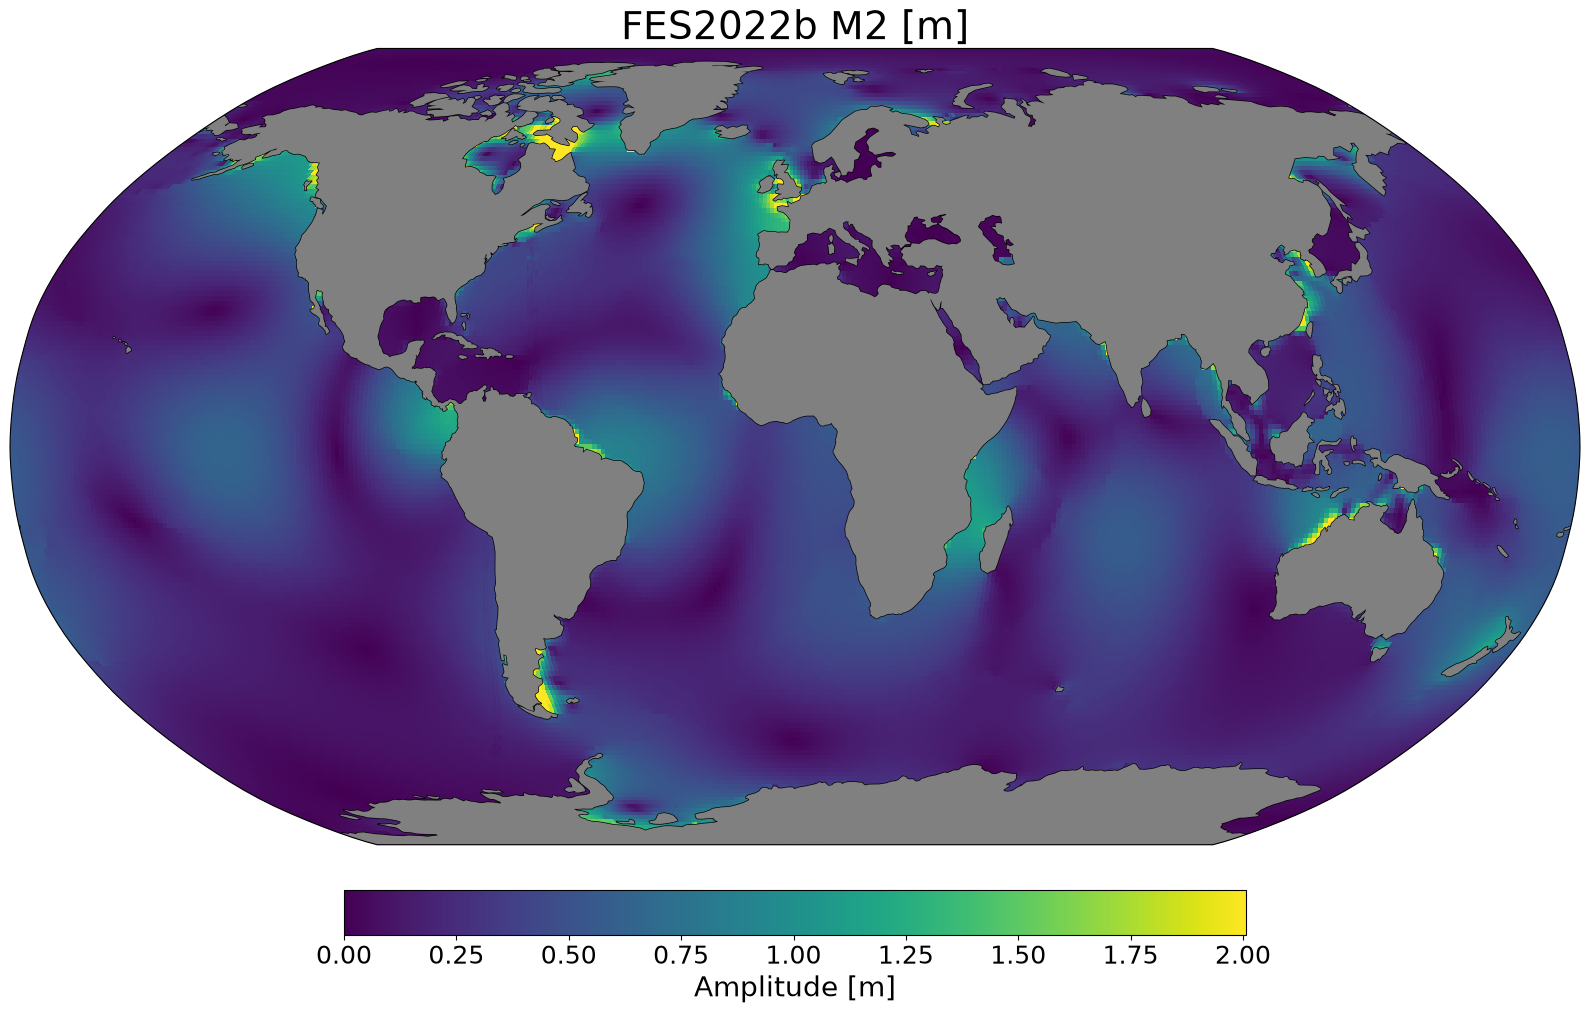

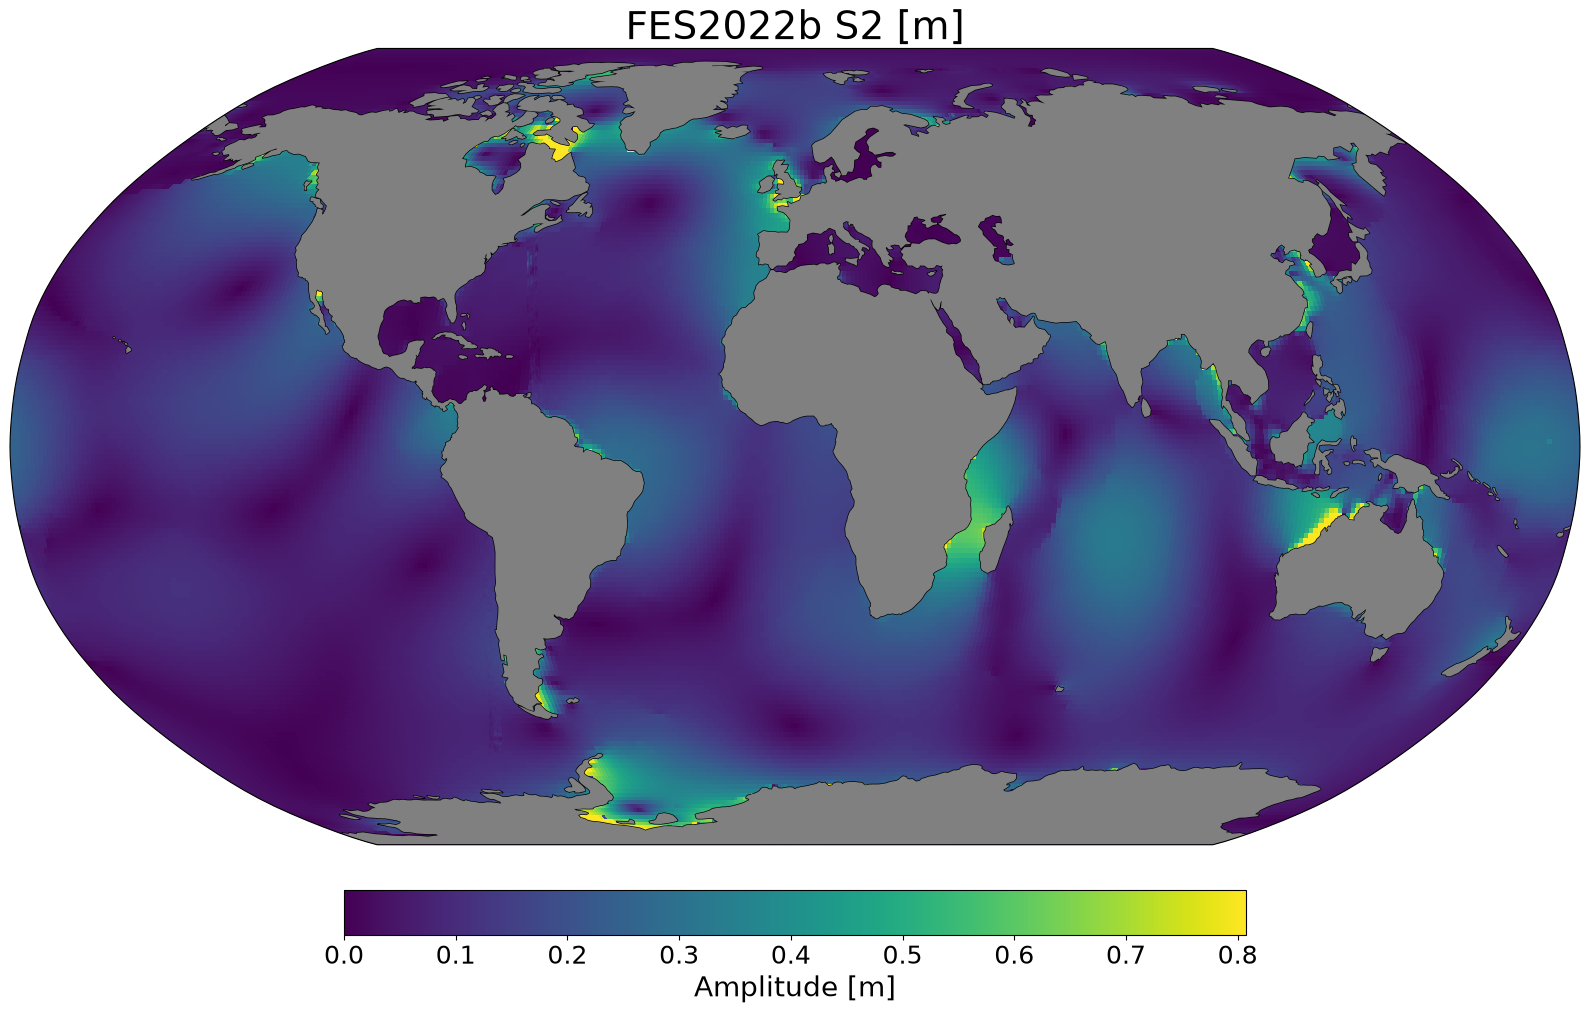

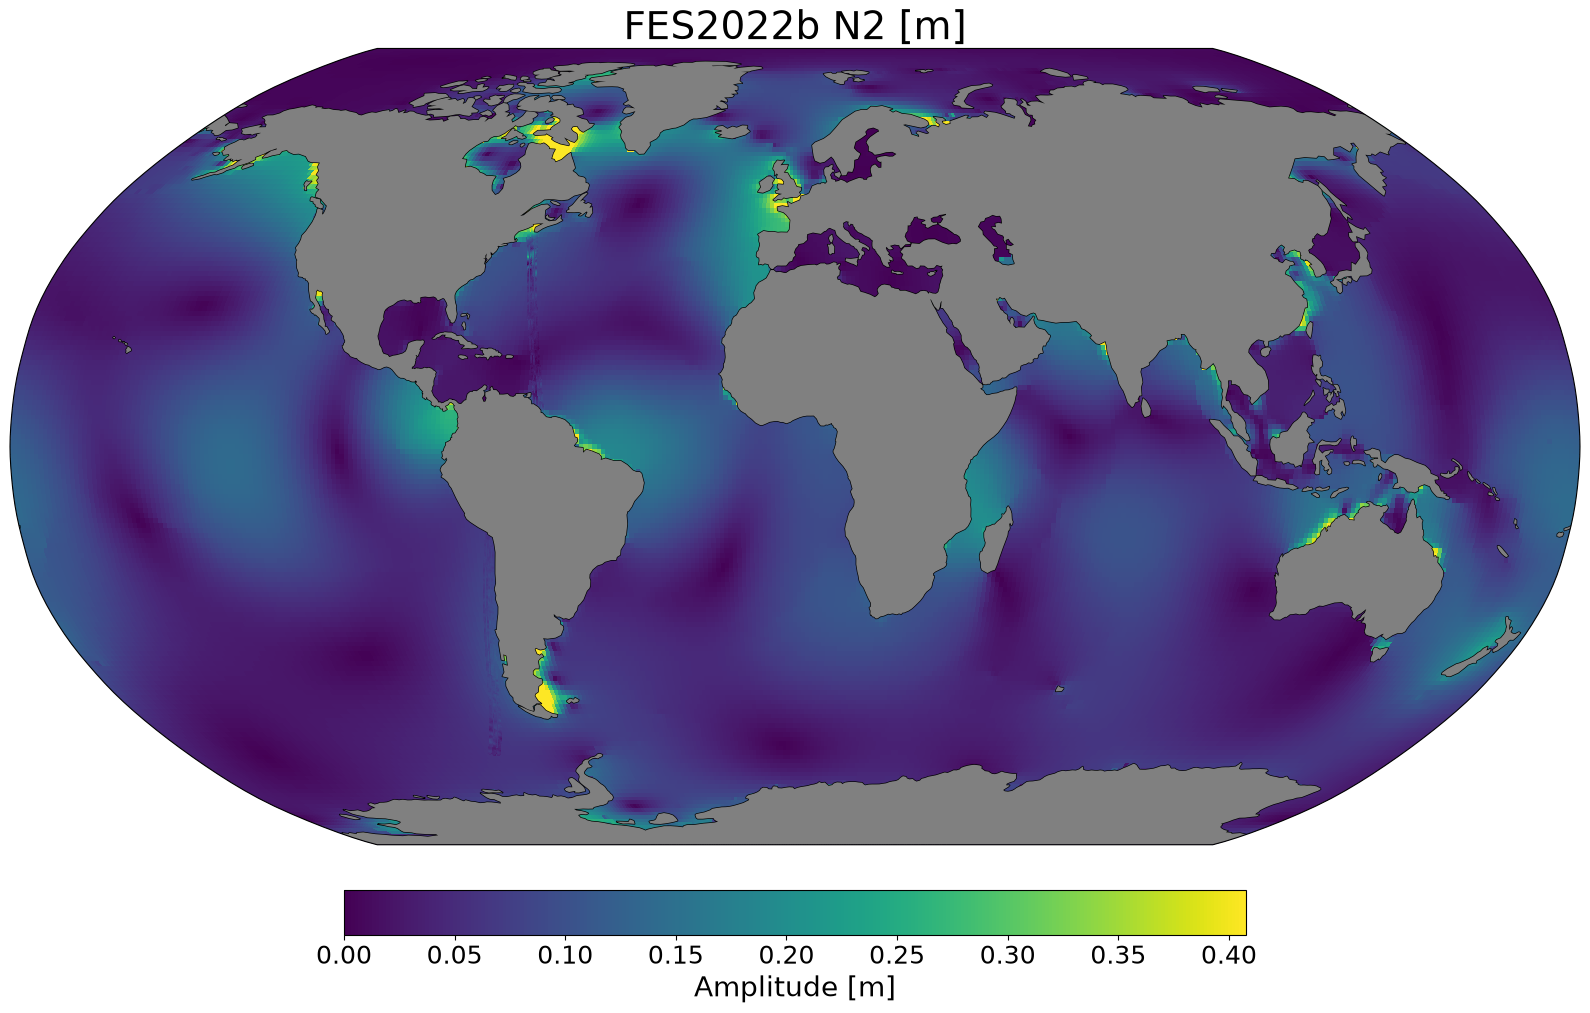

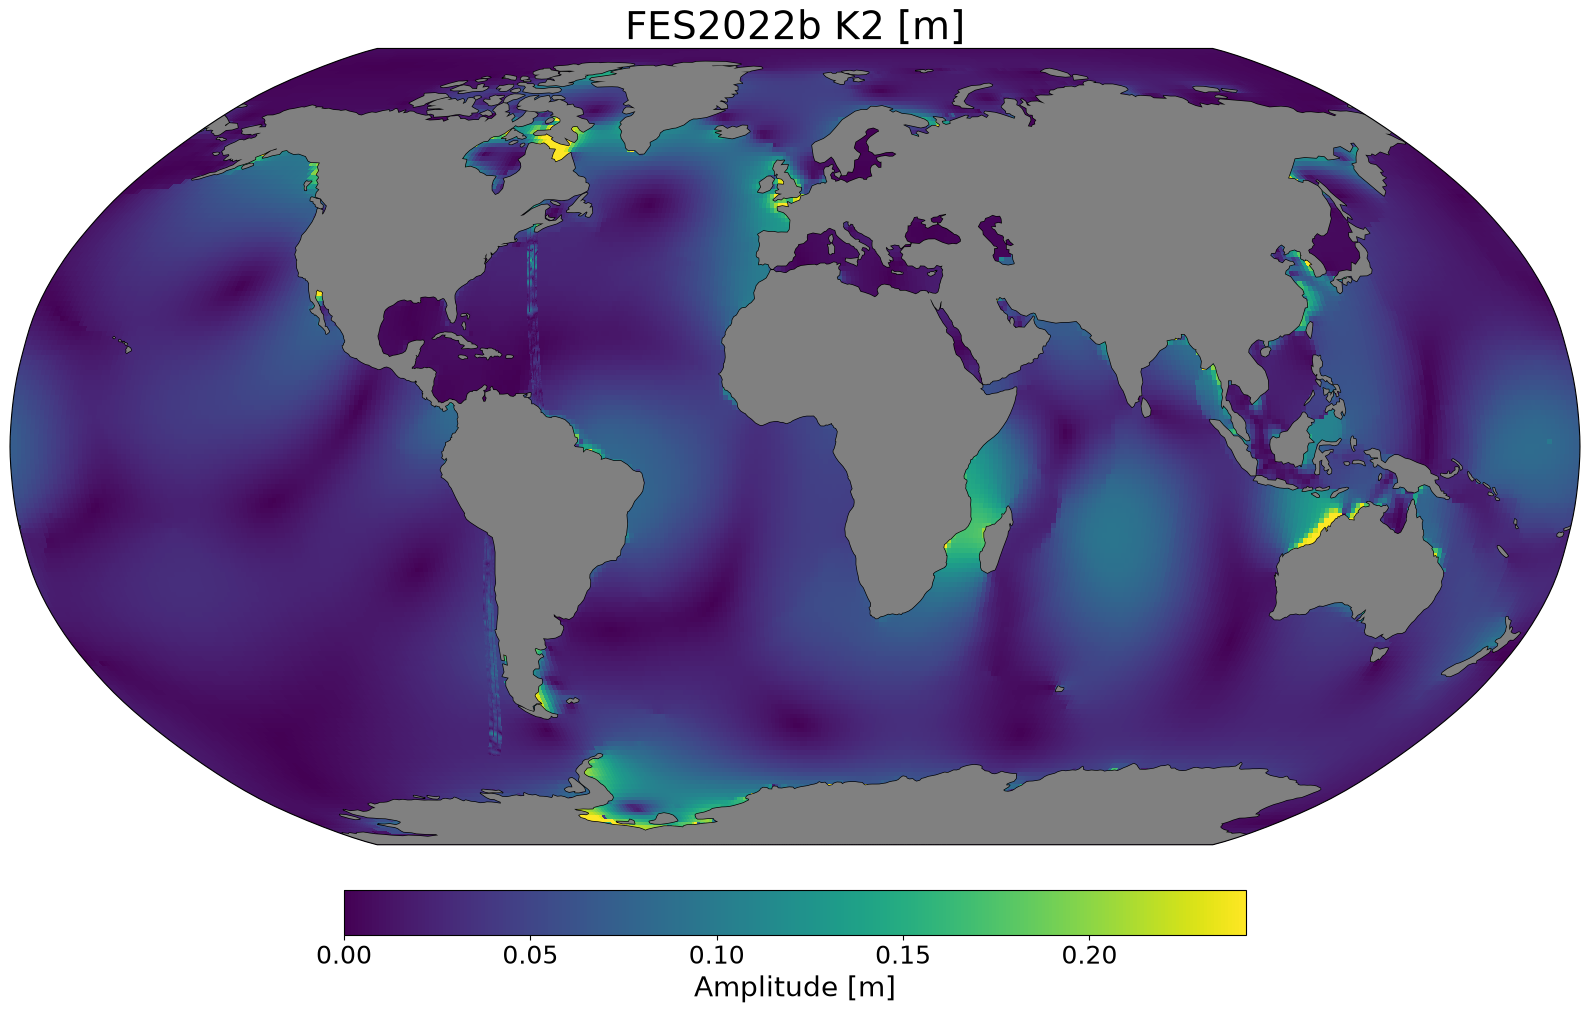

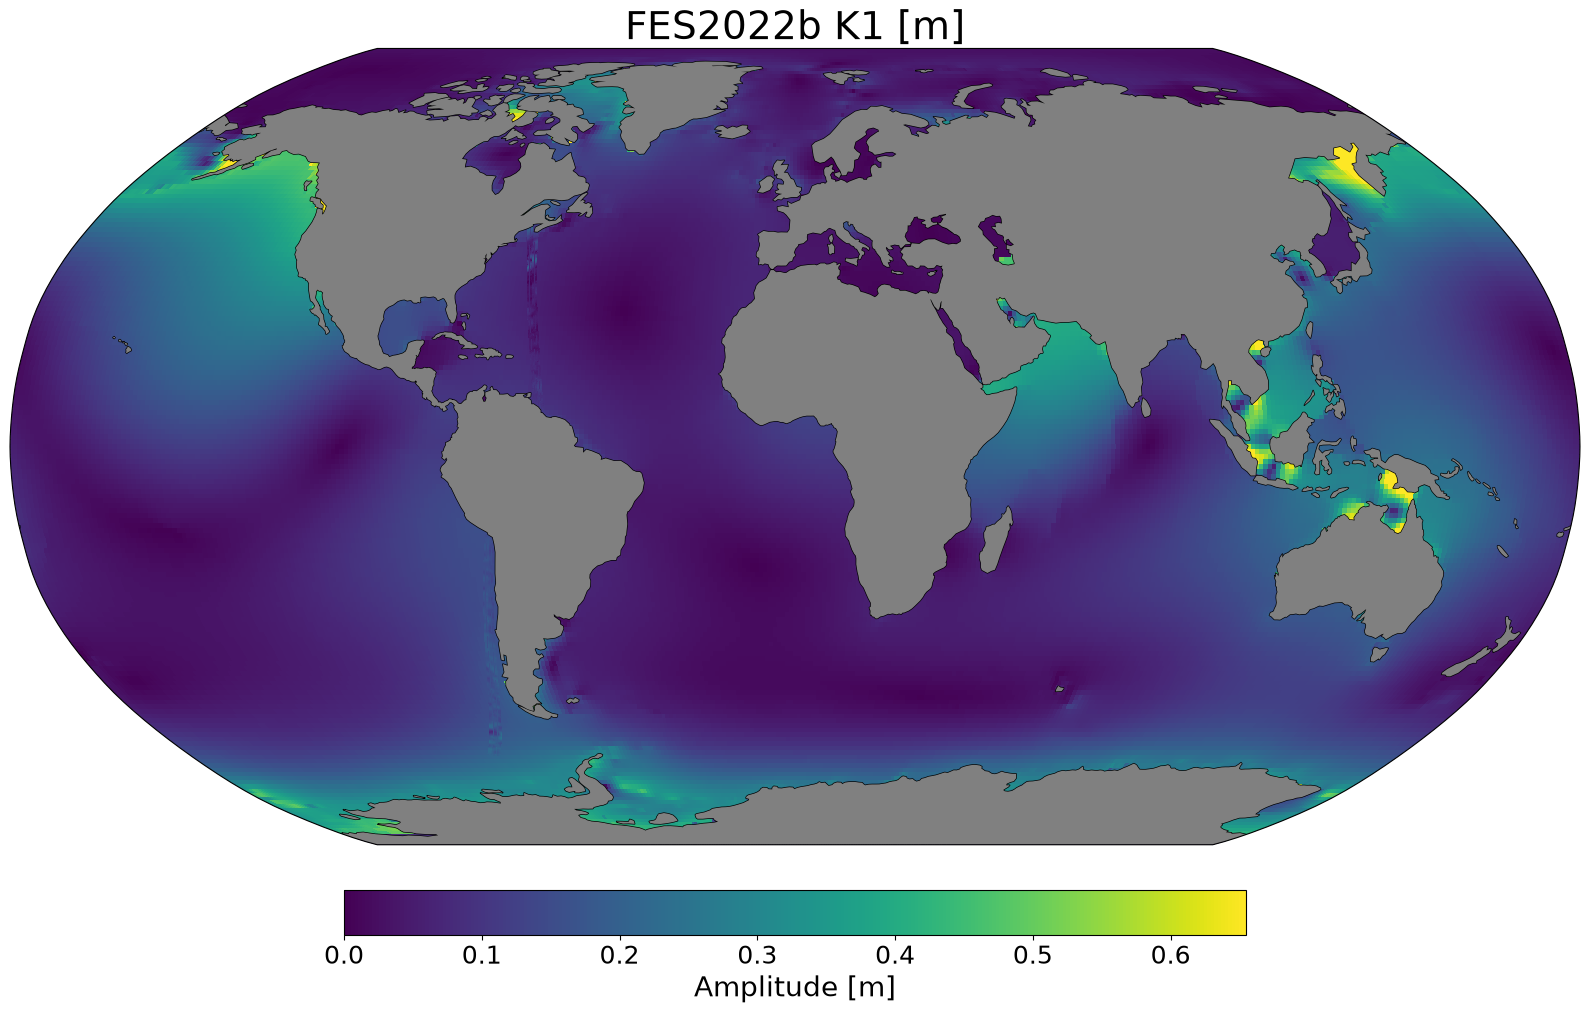

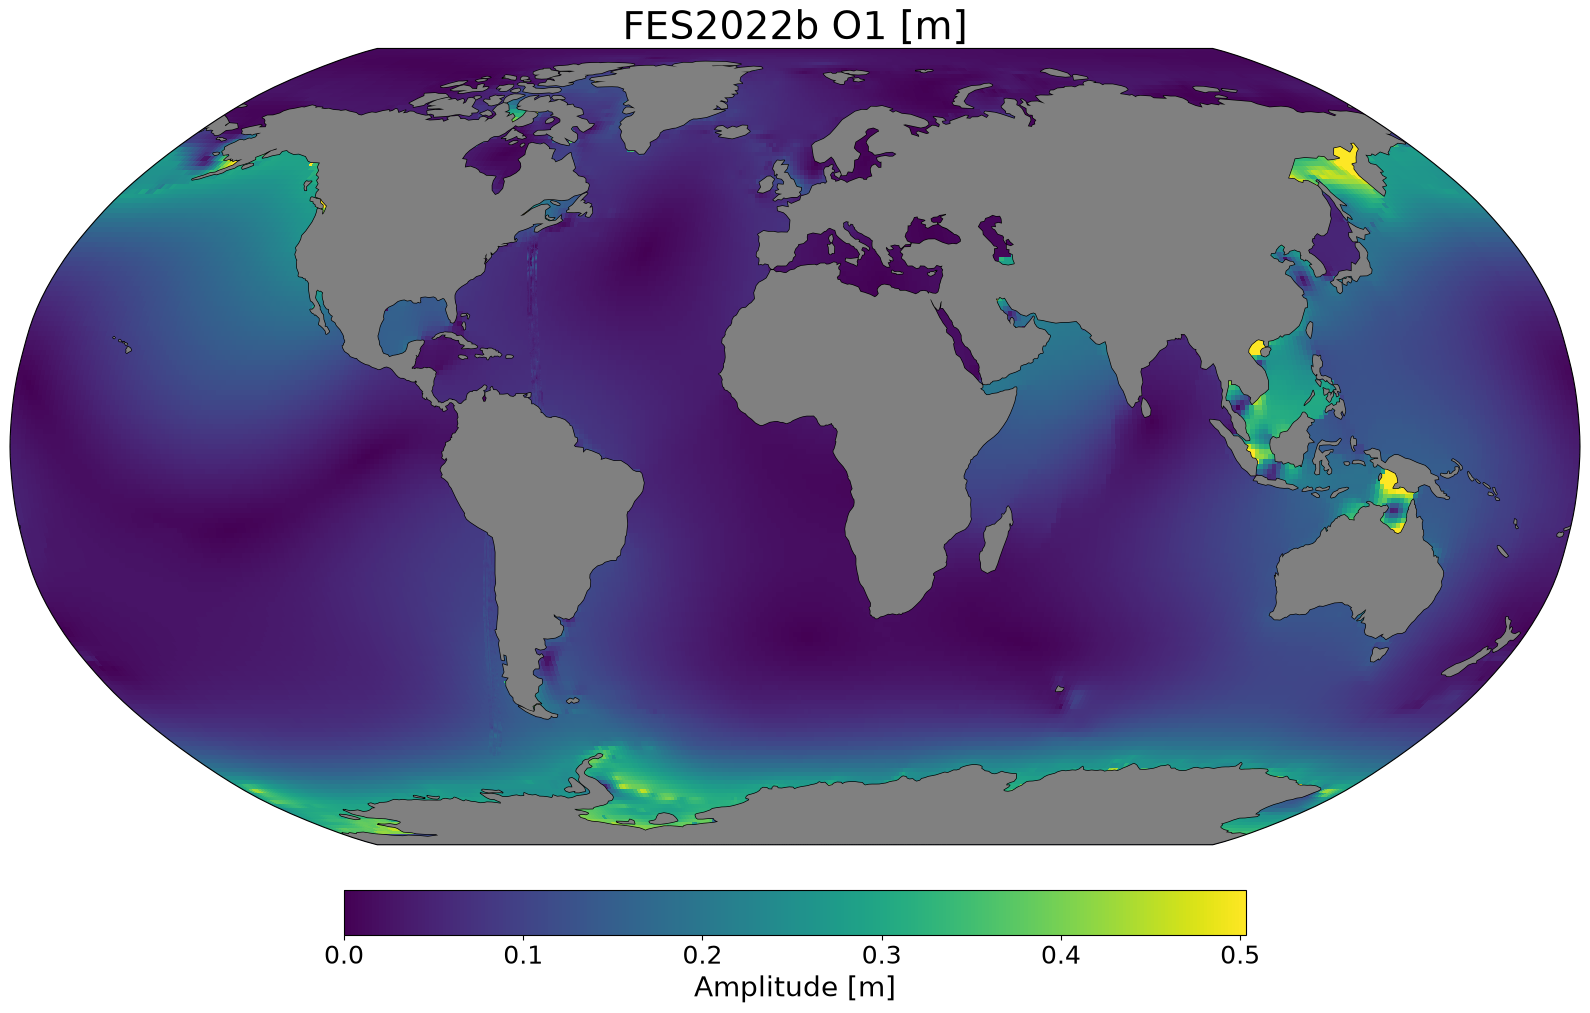

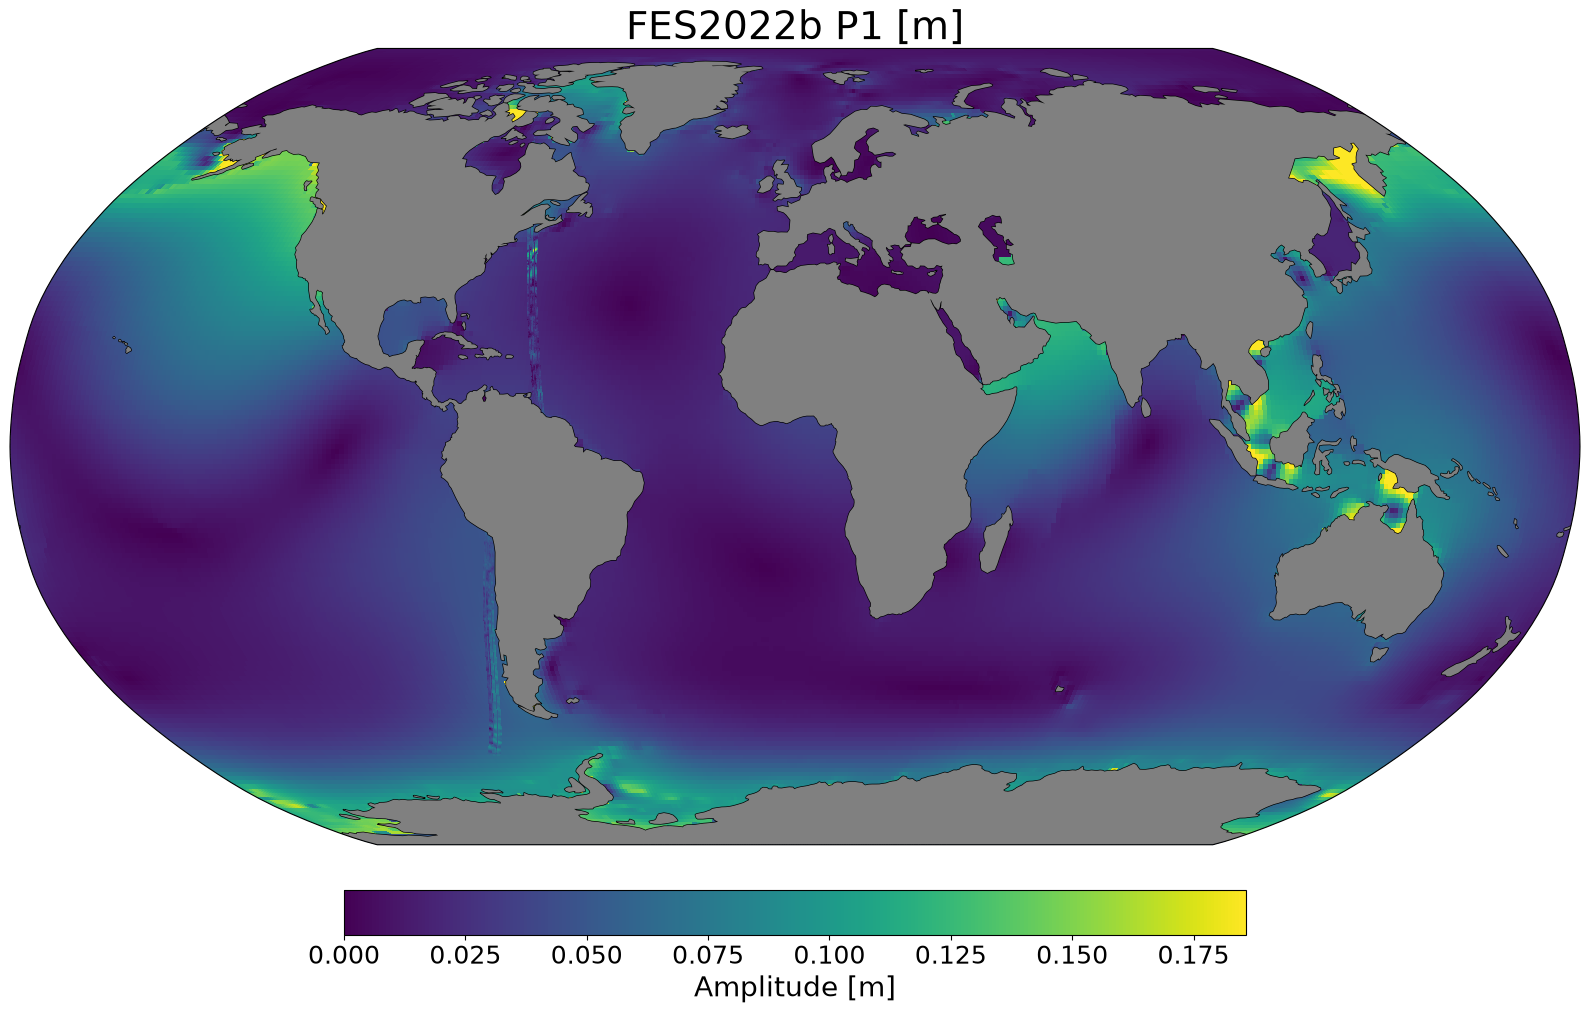

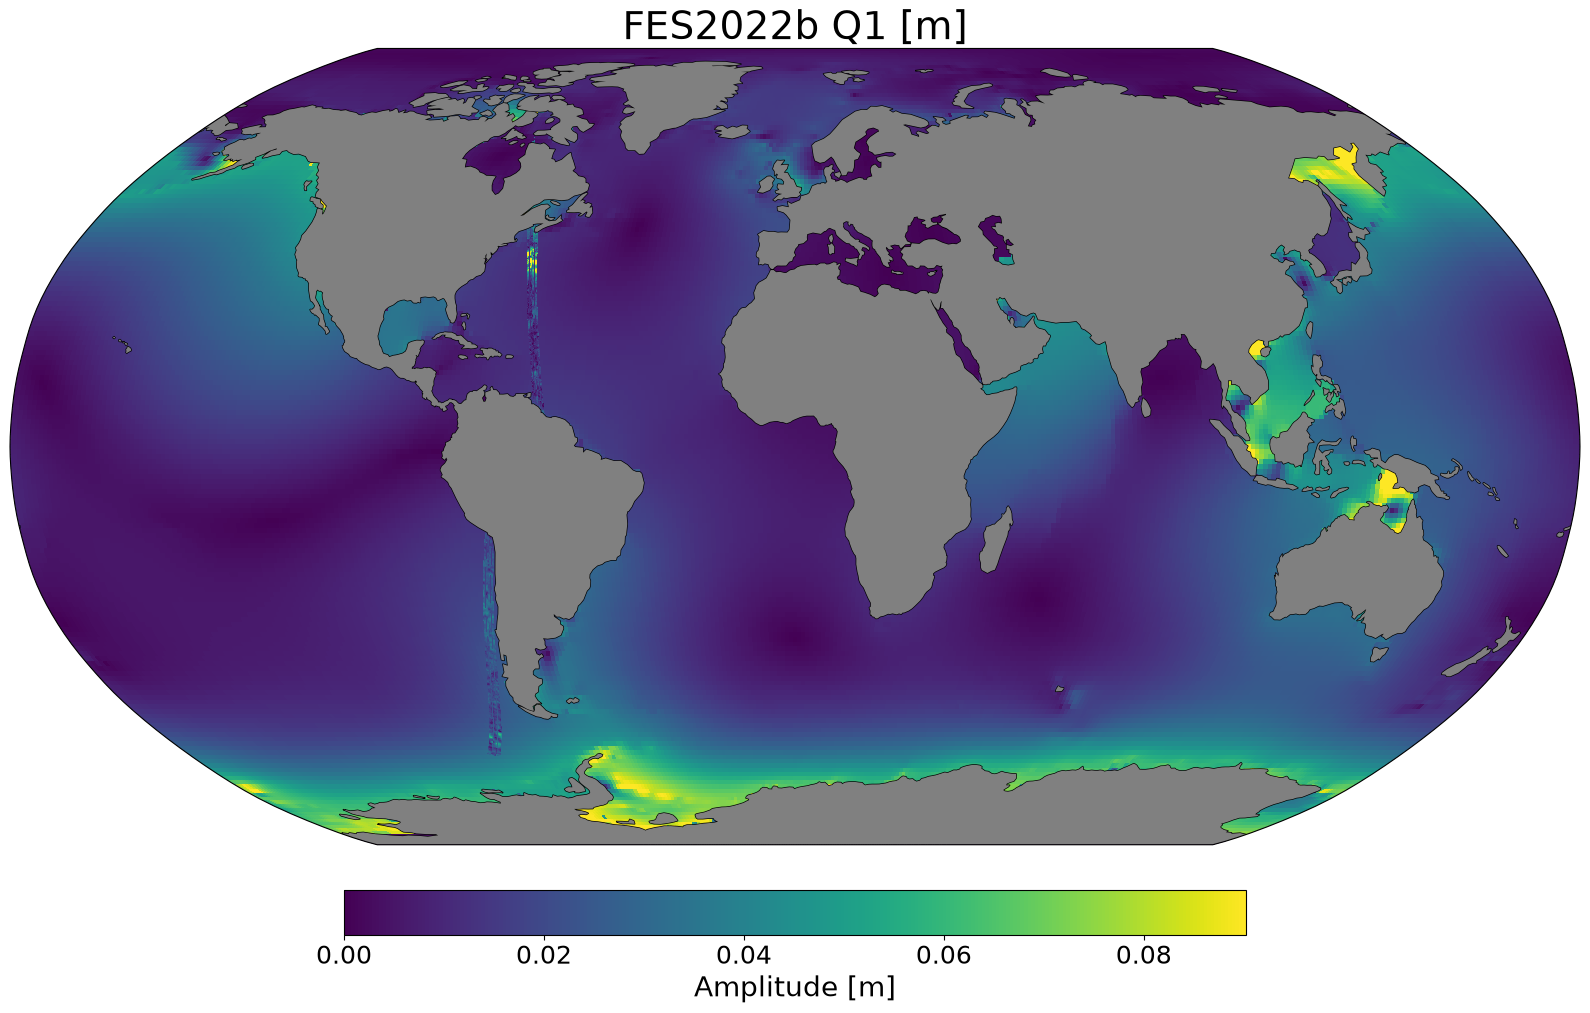

In [ ]:
projection = "robinson"
#projection = "spilhaus"

constits = ["M2", "S2", "N2", "K2", "K1", "O1", "P1", "Q1"]
for constituent in constits[:]:
    print(f"Plotting {constituent}")
    if projection == "spilhaus":
        fig_got, ax = plt.subplots(1, 1, figsize=(16, 10), subplot_kw={"projection": ccrs.Spilhaus()})
    elif projection == "robinson":
        fig_got, ax = plt.subplots(1, 1, figsize=(16, 10), subplot_kw={"projection": ccrs.Robinson()})
    title = f"FES2022b {constituent} [m]"
    cmap = "viridis"

    # Get 98th percentile for colorbar limits
    k = constits.index(constituent)
    amp_got = amp[k, :]
    limit = (0, np.nanpercentile(amp_got, 98))

    if projection == "spilhaus":
        mask = get_spilhaus_mask(lon_raveled, lat_raveled, ccrs.Spilhaus())
        amp_got = np.ma.masked_where(mask, amp_got)
    
    amp_got = amp_got.reshape((lat.size, lon.size))

    ax.pcolormesh(
        lon,
        lat,
        amp_got,
        cmap=cmap,
        vmin=limit[0],
        vmax=limit[1],
        shading="auto",
        transform=ccrs.PlateCarree(),
        rasterized=True
    )

    # Plot SWOT on top
    swot_dfs = sorted(Path("./_Data/SWOT_Tide_Results").glob("swot_tide_fit_pass_*.nc"))
    for df_path in swot_dfs:
        swot_df = xr.open_dataset(df_path)
        lon_swot = swot_df["longitude"].values
        lat_swot = swot_df["latitude"].values

        variables = [
            swot_df["amplitude"].isel(constituent=k).values,
            swot_df["amp_got"].isel(constituent=k).values,
            swot_df["vec"].isel(constituent=k).values
        ]
                
        for i, v in enumerate(variables):
            valid = (
                np.isfinite(v)
                & np.isfinite(lon_swot)
                & np.isfinite(lat_swot)
            )
            v = np.where(valid, v, np.nan)
            variables[i] = v


            sc = ax.pcolormesh(
                lon_swot,
                lat_swot,
                swot_df["amplitude"].isel(constituent=k).values,
                cmap=cmap,
                vmin=limit[0],
                vmax=limit[1],
                shading="auto",
                transform=ccrs.PlateCarree(),
                rasterized=True
            )

    ax.coastlines()
    ax.add_feature(
        cfeature.LAND,
        facecolor="gray",
        edgecolor="none",
        zorder=2
    )
    ax.set_title(title, fontsize=28)
    sm = plt.cm.ScalarMappable(
        norm=plt.Normalize(*limit),
        cmap=cmap
    )
    cbar = plt.colorbar(
        sm,
        ax=ax,
        orientation="horizontal",
        pad=0.05,
        fraction=0.05
    )
    cbar.ax.tick_params(labelsize=18)
    cbar.set_label("Amplitude [m]", fontsize=20)

    if projection == "spilhaus":
        ax.set_global()
    elif projection == "robinson":
        ax.set_global()

    fig_got.tight_layout()
    fig_got.savefig(f"./FES_{constituent}", dpi=300)